Input: /home/chenwu/Documents/Github/VLA_HIL/jetson_orin_nx/benchmark
Input records: 2160 | reported summary rows: 72
Power waveform included? False
{
  "repetitions": 3,
  "samples_per_config": 20,
  "sampling_interval_s": 0.002,
  "warmup_runs": 20,
  "seed": 7,
  "task_selection": "both"
}
NVPModel: NV Power Mode: MAXN
0
Model: nx_multitask_v2
Cameras: ['observation.images.camera1']
Tasks in records: {'grasping': 1080, 'pushing': 1080}
Legacy benchmark rows (excluded): 36


,config_id,repetition_id,sample_id,requested_cpu_mhz,actual_cpu_mhz,requested_gpu_mhz,actual_gpu_mhz,task_name,inference_ms,power_w,energy_j,wall_duration_s,start_monotonic_s,end_monotonic_s,frequency_valid,device,model_name
0,0,0,0,1984.0,1984.0,510.0,510.0,grasping,1318.119986,7.905463,10.437952,1.321257,113785.007019,113786.328276,True,cuda,nx_multitask_v2
1,0,0,1,1984.0,1984.0,510.0,510.0,pushing,819.475777,8.640435,7.094121,0.821627,113786.484614,113787.306241,True,cuda,nx_multitask_v2
2,0,0,2,1984.0,1984.0,510.0,510.0,grasping,818.517636,8.625831,7.072045,0.820449,113787.463349,113788.283797,True,cuda,nx_multitask_v2
3,0,0,3,1984.0,1984.0,510.0,510.0,pushing,818.294750,8.624072,7.049322,0.820153,113788.439975,113789.260128,True,cuda,nx_multitask_v2
4,0,0,4,1984.0,1984.0,510.0,510.0,grasping,821.612991,8.666024,7.121290,0.823775,113789.414237,113790.238012,True,cuda,nx_multitask_v2
5,0,0,5,1984.0,1984.0,510.0,510.0,pushing,823.815231,8.651427,7.138536,0.825758,113790.398517,113791.224275,True,cuda,nx_multitask_v2


Requested frequencies equal logged actual: 2160 / 2160
frequency_valid: {True: 2160}
Uploaded repetitions.csv rows: 2160 (expected 36 × 3 × 2 = 216 task-specific repetition rows)
Maximum difference to reported summary (ms): 4.547473508864641e-13
No power waveform included: True
Energy and mean power are recorded by device; waveform integration not independently verifiable.
Independent repetition/task rows: 216
Per-config per-task rows: 72


,requested_cpu_mhz,requested_gpu_mhz,n_samples,latency_mean_ms,latency_std_ms,latency_p95_ms,power_mean_w,energy_mean_j,edp_mean_j_s,frequency_valid,rep_latency_sd_ms,rep_energy_sd_j
33,1984.0,714.0,60,788.074,2.580,791.540,8.915,7.022,5.534,True,0.342,0.020
34,1984.0,816.0,60,790.069,1.857,793.440,9.041,7.140,5.641,True,0.535,0.020
35,1984.0,918.0,60,792.654,13.168,819.154,9.146,7.250,5.748,True,10.683,0.088
32,1984.0,612.0,60,793.479,4.678,798.602,8.792,6.975,5.535,True,1.150,0.032
31,1984.0,510.0,60,830.087,64.535,847.219,8.639,7.164,5.974,True,14.066,0.088
30,1984.0,408.0,60,844.287,7.021,849.305,8.489,7.162,6.047,True,2.099,0.008
29,1651.2,918.0,60,924.675,5.103,929.643,7.890,7.296,6.747,True,1.886,0.048
28,1651.2,816.0,60,929.942,1.734,933.592,7.770,7.227,6.720,True,0.692,0.008


,criterion,CPU MHz,GPU MHz,IL ms,Power W,Energy J,EDP J s
0,Lowest latency,1984.0,714.0,788.074,8.915,7.022,5.534
1,Lowest power,422.4,408.0,3121.733,5.612,17.525,54.749
2,Lowest reported energy,1984.0,612.0,793.479,8.792,6.975,5.535
3,Lowest EDP,1984.0,714.0,788.074,8.915,7.022,5.534
4,Highest latency,422.4,510.0,3126.470,5.673,17.744,55.553
5,Highest energy,422.4,918.0,3007.502,6.475,19.481,58.635


Latency range 788.07–3126.47 ms
Latency reduction slowest→fastest: 74.8%
CPU-level averages (six GPU settings each):


,latency_mean_ms,power_mean_w,energy_mean_j
requested_cpu_mhz,,,
422.4,3053.587,5.962,18.198
729.6,1852.350,6.309,11.671
1036.8,1402.693,6.598,9.232
1344.0,1126.335,6.974,7.848
1651.2,945.810,7.636,7.218
1984.0,806.442,8.837,7.119


GPU-level averages (six CPU settings each):


,latency_mean_ms,power_mean_w,energy_mean_j
requested_gpu_mhz,,,
408.0,1582.049,6.716,10.027
510.0,1578.632,6.788,10.089
612.0,1545.526,6.922,10.076
714.0,1507.689,7.075,10.114
816.0,1492.961,7.286,10.343
918.0,1480.359,7.528,10.638


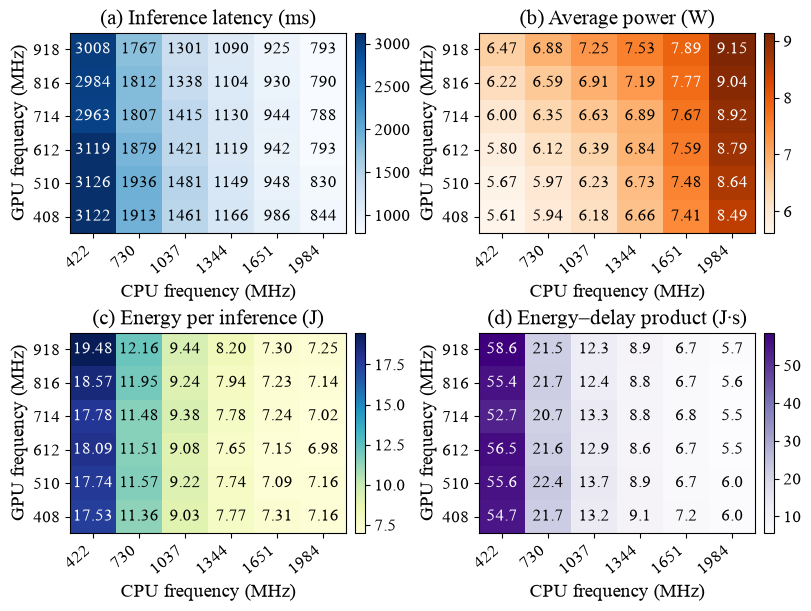

In [18]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
DATA_DIR = ROOT / 'data' if (ROOT / 'data' / 'inferences.csv').exists() else ROOT
FIG_DIR = ROOT / 'figures'
OUT_DIR = ROOT / 'results'
FIG_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)

cfg = json.loads((OUT_DIR / 'config.json').read_text())
raw = pd.read_csv(OUT_DIR / 'inferences.csv')
reported = pd.read_csv(OUT_DIR / 'summary.csv')
repetitions_uploaded = pd.read_csv(OUT_DIR / 'repetitions.csv')
legacy = pd.read_csv(OUT_DIR / 'smolvla_dvfs.csv')

plt.rcParams.update({'font.family': 'Times New Roman',
                     'font.sans-serif': ['Times New Roman', 'DejaVu Sans'],
                     'font.size': 12,
                     'axes.titlesize': 13,
                     'axes.labelsize': 12,
                     'xtick.labelsize': 12,
                     'ytick.labelsize': 12,
                     'legend.fontsize': 12,
                     'pdf.fonttype': 42,
                     'savefig.bbox': 'tight'})

def save_figure(fig, name):
    fig.savefig(FIG_DIR / f'{name}.pdf', bbox_inches='tight')
    fig.savefig(FIG_DIR / f'{name}.png', dpi=230, bbox_inches='tight')
    plt.show()

print('Input:', DATA_DIR)
print('Input records:', len(raw), '| reported summary rows:', len(reported))
print('Power waveform included?', (DATA_DIR / 'power_samples.csv').exists())

print(json.dumps({k: cfg['experiment'].get(k) for k in
                  ['repetitions','samples_per_config','sampling_interval_s','warmup_runs','seed','task_selection']}, indent=2))
print('NVPModel:', cfg.get('nvpmodel', {}).get('status'))
print('Model:', cfg.get('model', {}).get('name'))
print('Cameras:', cfg.get('input', {}).get('camera_keys'))
print('Tasks in records:', raw['task_name'].value_counts().to_dict())
print('Legacy benchmark rows (excluded):', len(legacy))
display(raw.head(6))

req = ['config_id','repetition_id','sample_id','requested_cpu_mhz','actual_cpu_mhz',
       'requested_gpu_mhz','actual_gpu_mhz','task_name','inference_ms','power_w',
       'energy_j','wall_duration_s','start_monotonic_s','end_monotonic_s','frequency_valid']
missing = set(req) - set(raw.columns)
assert not missing, f'Missing required columns: {missing}'
assert not raw.duplicated(['config_id','repetition_id','sample_id']).any()
assert np.isfinite(raw.select_dtypes(include=np.number).to_numpy()).all()
assert (raw[['inference_ms','power_w','energy_j','wall_duration_s']]>0).all().all()
assert np.allclose(raw.end_monotonic_s-raw.start_monotonic_s, raw.wall_duration_s, atol=1e-7)
assert raw.groupby(['config_id','repetition_id']).size().eq(20).all()
assert raw.groupby(['config_id','repetition_id','task_name']).size().eq(10).all()
assert raw.config_id.nunique() == 36 and raw.repetition_id.nunique() == 3

freq_match = (np.isclose(raw.requested_cpu_mhz,raw.actual_cpu_mhz) &
              np.isclose(raw.requested_gpu_mhz,raw.actual_gpu_mhz))
print('Requested frequencies equal logged actual:', int(freq_match.sum()), '/', len(raw))
print('frequency_valid:', raw.frequency_valid.value_counts().to_dict())
print('Uploaded repetitions.csv rows:',len(repetitions_uploaded),
      '(expected 36 × 3 × 2 = 216 task-specific repetition rows)')
if len(repetitions_uploaded)==len(raw):
    print('WARNING: repetitions.csv repeats per-inference values. Recompute from raw records.')

recomputed_check=raw.groupby(['config_id','task_name']).inference_ms.mean().rename('recomputed')
check = reported.set_index(['config_id','task_name']).join(recomputed_check)
print('Maximum difference to reported summary (ms):',
      float((check.mean_inference_ms-check.recomputed).abs().max()))
print('No power waveform included:', not (DATA_DIR/'power_samples.csv').exists())
print('Energy and mean power are recorded by device; waveform integration not independently verifiable.')

raw = raw.copy()
raw['edp_j_s'] = raw['energy_j'] * raw['inference_ms'] / 1000.0
freq_cols=['requested_cpu_mhz','requested_gpu_mhz']
repetition_summary = raw.groupby(['config_id','repetition_id','task_name',*freq_cols],as_index=False).agg(
    n_samples=('inference_ms','size'),
    latency_mean_ms=('inference_ms','mean'), latency_p95_ms=('inference_ms', lambda a: np.percentile(a,95)),
    power_mean_w=('power_w','mean'), energy_mean_j=('energy_j','mean'),
    edp_mean_j_s=('edp_j_s','mean'), frequency_valid=('frequency_valid','all'))

per_task = raw.groupby(['config_id',*freq_cols,'task_name'],as_index=False).agg(
    n_samples=('inference_ms','size'), latency_mean_ms=('inference_ms','mean'),
    latency_std_ms=('inference_ms','std'), latency_median_ms=('inference_ms','median'),
    latency_p95_ms=('inference_ms', lambda a: np.percentile(a,95)),
    latency_p99_ms=('inference_ms', lambda a: np.percentile(a,99)),
    power_mean_w=('power_w','mean'), energy_mean_j=('energy_j','mean'),
    energy_std_j=('energy_j','std'), edp_mean_j_s=('edp_j_s','mean'),
    frequency_valid=('frequency_valid','all'))

per_config=raw.groupby(freq_cols,as_index=False).agg(
    n_samples=('inference_ms','size'),
    latency_mean_ms=('inference_ms','mean'),
    latency_std_ms=('inference_ms','std'),
    latency_p95_ms=('inference_ms', lambda a: np.percentile(a,95)),
    power_mean_w=('power_w','mean'),energy_mean_j=('energy_j','mean'),
    edp_mean_j_s=('edp_j_s','mean'),
    frequency_valid=('frequency_valid','all'))

# Repetition-level spread for 3 independent rounds (not standard error of all 60 inferences).
rep_overall = raw.groupby([*freq_cols,'repetition_id'],as_index=False).agg(
    latency_mean_ms=('inference_ms','mean'), energy_mean_j=('energy_j','mean'))
rep_spread=rep_overall.groupby(freq_cols,as_index=False).agg(
    rep_latency_sd_ms=('latency_mean_ms','std'),rep_energy_sd_j=('energy_mean_j','std'))
per_config = per_config.merge(rep_spread,on=freq_cols)

assert len(repetition_summary)==216 and len(per_task)==72 and len(per_config)==36
print('Independent repetition/task rows:',len(repetition_summary))
print('Per-config per-task rows:',len(per_task))
display(per_config.sort_values('latency_mean_ms').head(8).round(3))

repetition_summary.to_csv(OUT_DIR/'repetitions_corrected.csv',index=False)
per_task.to_csv(OUT_DIR/'per_task_summary.csv',index=False)
per_config.to_csv(OUT_DIR/'per_config_summary.csv',index=False)

criteria={'Lowest latency':('latency_mean_ms','min'),
          'Lowest power':('power_mean_w','min'),
          'Lowest reported energy':('energy_mean_j','min'),
          'Lowest EDP':('edp_mean_j_s','min'),
          'Highest latency':('latency_mean_ms','max'),
          'Highest energy':('energy_mean_j','max')}
rows=[]
for name,(field,ext) in criteria.items():
    i = per_config[field].idxmin() if ext=='min' else per_config[field].idxmax()
    row=per_config.loc[i]
    rows.append({'criterion':name,'CPU MHz':row.requested_cpu_mhz,'GPU MHz':row.requested_gpu_mhz,
                 'IL ms':row.latency_mean_ms,'Power W':row.power_mean_w,
                 'Energy J':row.energy_mean_j,'EDP J s':row.edp_mean_j_s})
key_results=pd.DataFrame(rows)
display(key_results.round(3))
key_results.to_csv(OUT_DIR/'key_results.csv',index=False)

slow=per_config.loc[per_config.latency_mean_ms.idxmax()]
fast=per_config.loc[per_config.latency_mean_ms.idxmin()]
print(f'Latency range {fast.latency_mean_ms:.2f}–{slow.latency_mean_ms:.2f} ms')
print(f'Latency reduction slowest→fastest: {100*(slow.latency_mean_ms-fast.latency_mean_ms)/slow.latency_mean_ms:.1f}%')
print(f'CPU-level averages (six GPU settings each):')
display(per_config.groupby('requested_cpu_mhz')[['latency_mean_ms','power_mean_w','energy_mean_j']].mean().round(3))
print('GPU-level averages (six CPU settings each):')
display(per_config.groupby('requested_gpu_mhz')[['latency_mean_ms','power_mean_w','energy_mean_j']].mean().round(3))

per_config = per_config.copy()
per_config['requested_cpu_mhz'] = np.rint(per_config['requested_cpu_mhz']).astype(int)
per_config['requested_gpu_mhz'] = np.rint(per_config['requested_gpu_mhz']).astype(int)
cpu_order = np.sort(per_config['requested_cpu_mhz'].unique())
gpu_order = np.sort(per_config['requested_gpu_mhz'].unique())

def plot_heatmap(ax, metric, title, label, cmap, fmt):
    mat = per_config.pivot(index='requested_gpu_mhz', columns='requested_cpu_mhz', values=metric)
    mat = mat.reindex(index=gpu_order, columns=cpu_order)
    im = ax.imshow(mat.values, origin='lower', aspect='auto', cmap=cmap)
    ax.set_xticks(range(len(cpu_order)))
    ax.set_xticklabels([f'{int(v)}' for v in cpu_order], rotation=40, ha='right')
    ax.set_yticks(range(len(gpu_order)))
    ax.set_yticklabels([f'{int(v)}' for v in gpu_order])
    ax.set_xlabel('CPU frequency (MHz)', fontsize=14)
    ax.set_ylabel('GPU frequency (MHz)', fontsize=14)
    ax.set_title(title, fontsize=15)
    for j in range(len(gpu_order)):
        for i in range(len(cpu_order)):
            val = mat.values[j, i]
            ax.text(i, j, format(val, fmt), fontsize=12, ha='center', va='center',
                    color='white' if im.norm(val) > 0.60 else 'black')
    cb = ax.figure.colorbar(im, ax=ax, fraction=.046, pad=.03)
    # cb.set_label(label, fontsize=11)

specs = [('latency_mean_ms', '(a) Inference latency (ms)', 'ms', 'Blues', '.0f'),
         ('power_mean_w', '(b) Average power (W)', 'W', 'Oranges', '.2f'),
         ('energy_mean_j', '(c) Energy per inference (J)', 'J', 'YlGnBu', '.2f'),
         ('edp_mean_j_s', '(d) Energy–delay product (J·s)', 'J·s', 'Purples', '.1f')]
fig, axs = plt.subplots(2, 2, figsize=(8, 6), layout='constrained')
for ax, (met, ttl, unit, cmap, fmt) in zip(axs.flat, specs):
    plot_heatmap(ax, met, ttl, unit, cmap, fmt)
plt.savefig(FIG_DIR / 'fig_dvfs_four_heatmaps.pdf', bbox_inches='tight')